# 01 · 文本→Token→批次与标签

**Source audit:** [karpathy/nanoGPT](https://github.com/karpathy/nanoGPT/tree/3adf61e154c3fe3fca428ad6bc3818b27a3b8291) at `3adf61e154c3`; relevant files: `model.py`, `train.py`, `sample.py`, `data/shakespeare_char/prepare.py`, `config/train_shakespeare_char.py`.

**Scope:** The notebook uses a small **educational adaptation** (`nanogpt_edu.py`) consistent with the original architecture, not a verbatim copy of the full upstream training program. No pretrained weights, external datasets, downloads, distributed GPUs, or performance reproduction are claimed. Figures and prints are generated by real local CPU executions. The project's README has marked nanoGPT deprecated since Nov 2025 and points to nanochat.

## 字符级 Tokenization

对应上游 `data/shakespeare_char/prepare.py`：对语料字符去重、编号，然后把整段文本表示为整数序列。不同于 GPT-2 BPE，这里不依赖 `tiktoken`；我们用原创短文本做离线演示。

In [1]:
from pathlib import Path
import sys, torch, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
# Compatible with starting Jupyter from the notebook directory OR repository root.
P = Path.cwd().resolve()
ROOT = P if (P / 'nanogpt_edu.py').exists() else P.parent
if not (ROOT / 'nanogpt_edu.py').exists():
    raise RuntimeError('Open this notebook from tutorials/nanogpt/notebooks or the tutorials/nanogpt directory')
sys.path.insert(0, str(ROOT))
from nanogpt_edu import GPTConfig, GPT, char_dataset, get_batch, training_text, lr_schedule, parameter_groups
OUT = ROOT / 'outputs'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(min(2, torch.get_num_threads()))
torch.manual_seed(42); np.random.seed(42)
print('Python:', sys.version.split()[0], '| PyTorch:', torch.__version__, '| CPU tutorial', '| path:', ROOT)

Python: 3.13.5 | PyTorch: 2.10.0+cpu | CPU tutorial | path: /mnt/notebook-builder/tutorials/nanogpt


Total chars: 2484 | vocabulary: 27
Original prefix: 'the moon follows the quiet sea.\nsmall models learn one token at a time.\na tiny transformer'
Encoded prefix: [23, 12, 9, 1, 16, 18, 18, 17, 1, 10, 18, 15, 15, 18, 25, 22, 1, 23, 12, 9, 1, 20, 24, 13, 9]
Decoded prefix: the moon follows the quie


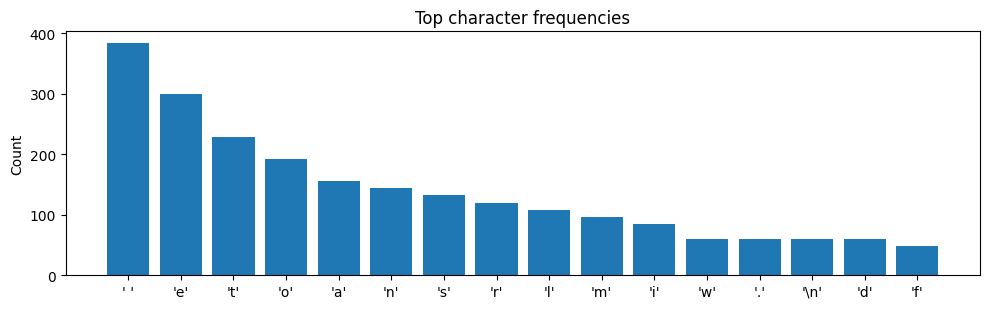

In [2]:
from collections import Counter
text = training_text(repeats=12)
ids, stoi, itos = char_dataset(text)
print('Total chars:', len(text), '| vocabulary:', len(stoi))
print('Original prefix:', repr(text[:90]))
print('Encoded prefix:', ids[:25].tolist())
print('Decoded prefix:', ''.join(itos[i] for i in ids[:25].tolist()))
assert ''.join(itos[i] for i in ids.tolist()) == text
counts = Counter(text)
common = counts.most_common(16)
fig, ax = plt.subplots(figsize=(10, 3.2)); ax.bar([repr(k) for k,v in common], [v for k,v in common])
ax.set_title('Top character frequencies'); ax.set_ylabel('Count'); fig.tight_layout()
fig.savefig(FIG / '01_character_hist.png', dpi=130); display(fig); plt.close(fig)

X (first row): [16, 1, 15, 9, 10, 23, 1, 23, 18, 1, 21, 13] => 'm left to ri'
Y (first row): [1, 15, 9, 10, 23, 1, 23, 18, 1, 21, 13, 11] => ' left to rig'


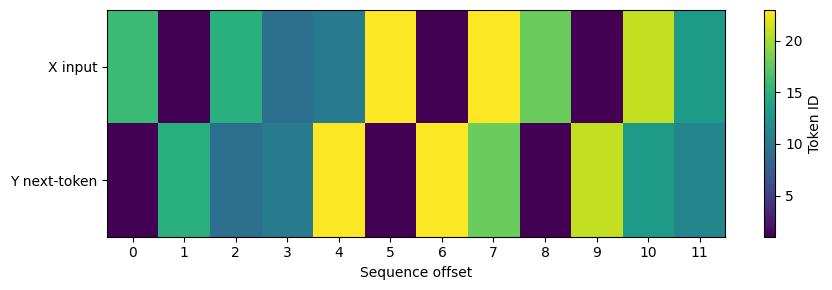

In [3]:
X, Y = get_batch(ids, block_size=12, batch_size=4, generator=torch.Generator().manual_seed(9))
print('X (first row):', X[0].tolist(), '=>', repr(''.join(itos[i] for i in X[0].tolist())))
print('Y (first row):', Y[0].tolist(), '=>', repr(''.join(itos[i] for i in Y[0].tolist())))
assert torch.equal(X[0, 1:], Y[0, :-1])
fig, ax = plt.subplots(figsize=(9, 3)); image=ax.imshow(torch.stack((X[0],Y[0])).numpy(), aspect='auto')
ax.set_yticks([0,1],['X input','Y next-token']); ax.set_xticks(range(X.shape[1])); ax.set_xlabel('Sequence offset')
fig.colorbar(image, ax=ax, label='Token ID'); fig.tight_layout()
fig.savefig(FIG / '01_shifted_tokens.png', dpi=130); display(fig); plt.close(fig)

Unigram baseline entropy: 2.879 nats; uniform random guess: 3.296 nats


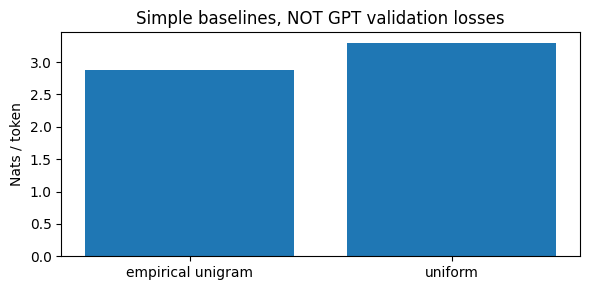

In [4]:
frequencies = torch.bincount(ids, minlength=len(stoi)).float(); p = frequencies / frequencies.sum()
entropy = -(p * torch.log(p.clamp_min(1e-12))).sum().item()
uniform = float(np.log(len(stoi)))
print(f'Unigram baseline entropy: {entropy:.3f} nats; uniform random guess: {uniform:.3f} nats')
fig, ax = plt.subplots(figsize=(6, 3));ax.bar(['empirical unigram', 'uniform'], [entropy, uniform]); ax.set_ylabel('Nats / token')
ax.set_title('Simple baselines, NOT GPT validation losses'); fig.tight_layout()
fig.savefig(FIG / '01_entropy_baselines.png', dpi=130); display(fig); plt.close(fig)

### 动手练习

1. 修改 `block_size=6`，列出 `X[0]` 的每个前缀能预测的下一个字符。
2. 解释为什么**数据切分**应在统计指标计算前确定，以及为何这里的 baseline 不是训练好的语言模型。